In [6]:
from yolo_rgbd.prediction import predict_from_array, load_npz

rgbd_path = "tests/test_files/fold_1/images/40_303320_5041760 (2025-07-02) (56m).npz"
model_path = "tests/test_files/models/yolo11n_species_rgbd_256_f1_60e.pt"

rgbd_array = load_npz(rgbd_path)
instances, semantics, confs = predict_from_array(model_path, rgbd_array, pred_mode='rgbd', confidence=0.2)


0: 256x256 8 trees, 3 acpls, 5 uls, 1 ceoc, 1 tico, 11.2ms
Speed: 0.4ms preprocess, 11.2ms inference, 1.2ms postprocess per image at shape (1, 3, 256, 256)


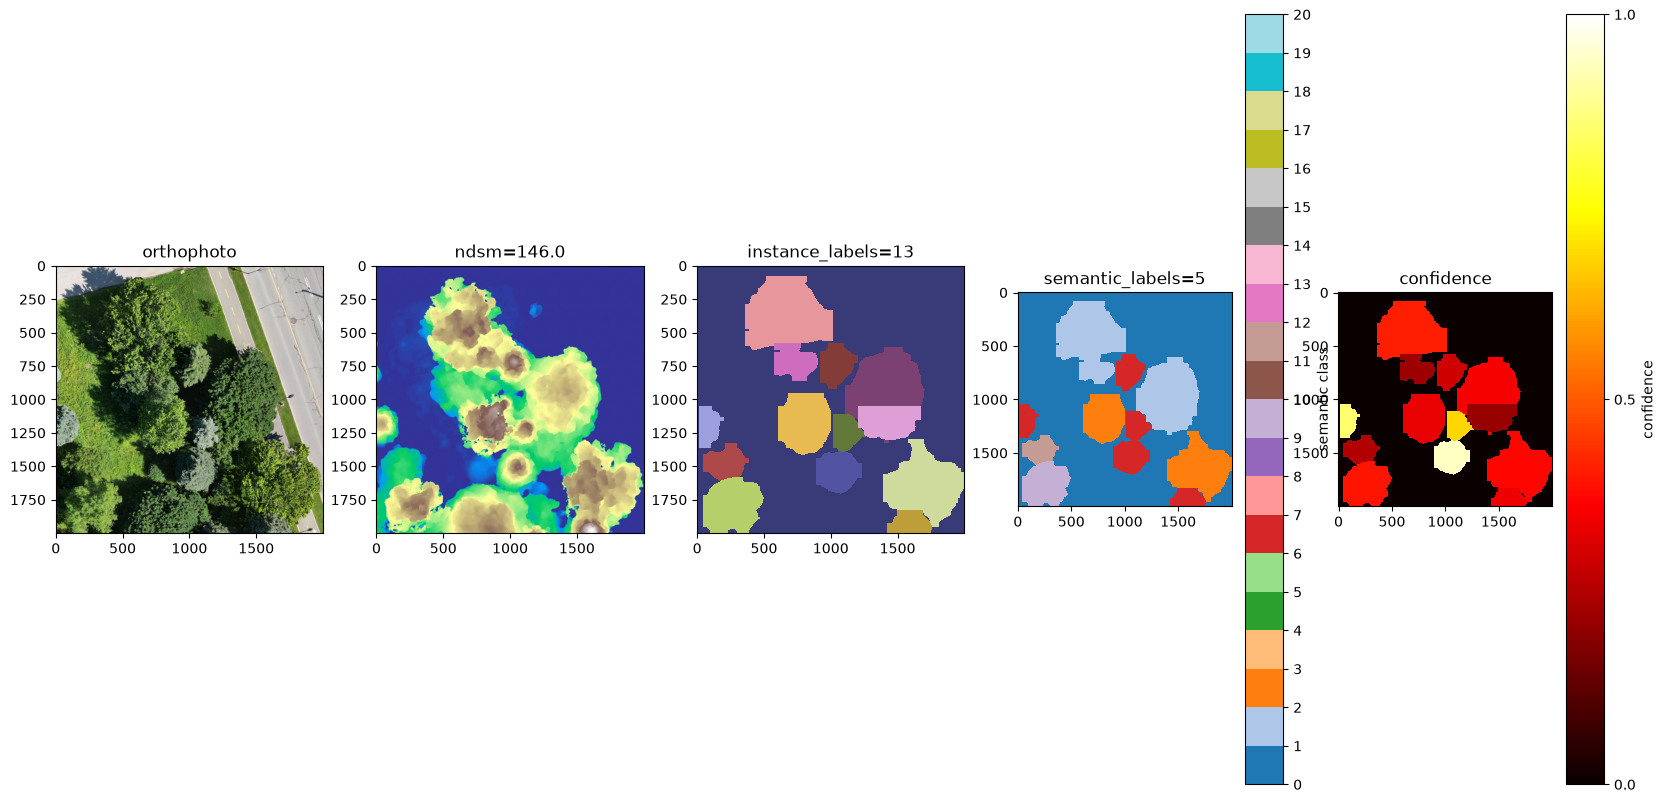

In [9]:
import matplotlib.pyplot as plt
import numpy as np

rgb = rgbd_array[:, :, :3]
d = rgbd_array[:, :, 3]

plt.subplots(1, 5, figsize=(20, 10))

plt.subplot(1, 5, 1)
plt.title(f'orthophoto')
plt.imshow(rgb)

plt.subplot(1, 5, 2)
max_v = np.max(d)
plt.title(f'ndsm={max_v:.1f}')
plt.imshow(d, cmap='terrain')

plt.subplot(1, 5, 3)
unique = len(np.unique(instances))
plt.title(f'instance_labels={unique - 1}')
plt.imshow(instances, cmap='tab20b', interpolation='nearest')

plt.subplot(1, 5, 4)
unique = len(np.unique(semantics)) - 1
plt.title(f'semantic_labels={unique}')
plt.imshow(semantics, vmin=0, vmax=20, cmap='tab20', interpolation='nearest')
plt.colorbar(ticks=range(21), label='semantic class')

plt.subplot(1, 5, 5)
plt.title(f'confidence')
plt.imshow(confs, vmin=0, vmax=1, cmap='hot', interpolation='nearest')
plt.colorbar(ticks=[0, 0.5, 1], label='confidence')

plt.show()